# RDKIT primer
Utilisation de la librairie RDKIT dans l'environnement de colaboratory

Références :


*   [RDKIT (wiki D. Villers)](https://dvillers.umons.ac.be/wiki/teaching:progappchim:rdkit)
*   [Installing RDKit in Google Colab (Stackoverflow)](https://stackoverflow.com/questions/63152656/installing-rdkit-in-google-colab)
*   [Pour mémoire, non utilisé : Install Conda and friends on Google Colab, easily (librairie condacolab)](https://github.com/conda-incubator/condacolab)




In [1]:
!pip install rdkit-pypi

ERROR: Could not find a version that satisfies the requirement rdkit-pypi (from versions: none)
ERROR: No matching distribution found for rdkit-pypi


In [4]:
    # from http://ctr.wikia.com/wiki/Depict_a_compound_as_an_image
    from rdkit.Chem import AllChem
    from rdkit.Chem import Draw
     
    smiles = "CN1C=NC2=C1C(=O)N(C(=O)N2C)C"
    mol = AllChem.MolFromSmiles(smiles)
     
    # technically this step isn't required since the drawing code
    # will automatically add a 2D conformation to a molecule that has
    # no conformation information, I'm including it to show how to
    # generate 2D coords with the RDKit:
    AllChem.Compute2DCoords(mol)
     
    Draw.MolToFile(mol,"caffeine.png",size=(200,250))



In [5]:
!ls -la

total 44
drwxr-xr-x 1 root root  4096 Mar 14 15:29 .
drwxr-xr-x 1 root root  4096 Mar 14 15:08 ..
-rw-r--r-- 1 root root  8782 Mar 14 15:29 caffeine.png
-rw-r--r-- 1 root root 14029 Mar 14 15:14 condacolab_install.log
drwxr-xr-x 1 root root  4096 Mar  9 14:47 .config
drwxr-xr-x 1 root root  4096 Mar  9 14:48 sample_data


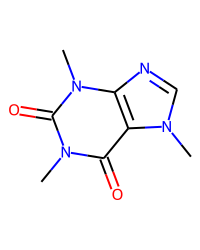

In [7]:
from IPython.display import Image
Image(filename='caffeine.png') 


In [2]:
# Dessine les 4 principaux en même temps
from rdkit.Chem import Draw

smiles_list = [
    ("Chloroquine", "CCN(CC)CCCC(C)NC1=C2C=CC(=CC2=NC=C1)Cl"),
    ("Amodiaquine", "CCN(CC)CC1=C(C=CC(=C1)NC2=C3C=CC(=CC3=NC=C2)Cl)O"),
    ("Quinine", "COC1=CC2=C(C=CN=C2C=C1)[C@H]([C@@H]3C[C@@H]4CCN3C[C@@H]4C=C)O"),
    ("Artemether", "CO[C@@H]1O[C@H]2[C@@H](C)CC[C@H]3[C@H]2[C@@H](O1)O[C@@H]4[C@@]3(C)CC[C@H](C4)C")
]

mols = [Chem.MolFromSmiles(s) for nom, s in smiles_list]
legends = [nom for nom, s in smiles_list]

Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(250,250), legends=legends)

NameError: name 'Chem' is not defined

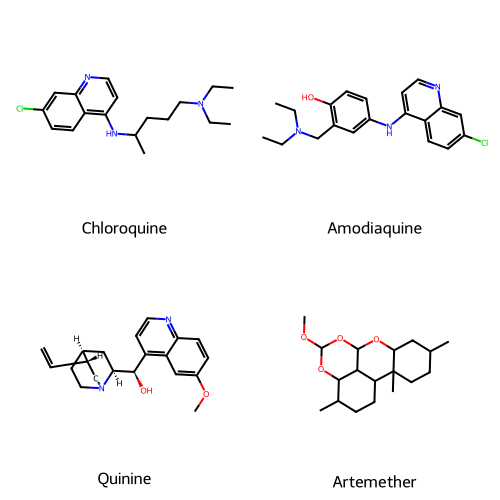

In [3]:
from rdkit import Chem
from rdkit.Chem import Draw

smiles_list = [
    ("Chloroquine", "CCN(CC)CCCC(C)NC1=C2C=CC(=CC2=NC=C1)Cl"),
    ("Amodiaquine", "CCN(CC)CC1=C(C=CC(=C1)NC2=C3C=CC(=CC3=NC=C2)Cl)O"),
    ("Quinine", "COC1=CC2=C(C=CN=C2C=C1)[C@H]([C@@H]3C[C@@H]4CCN3C[C@@H]4C=C)O"),
    ("Artemether", "COC1OC2C(C)CCC3C2C(O1)OC1C3(C)CCC(C1)C")
]

mols = [Chem.MolFromSmiles(s) for nom, s in smiles_list]
legends = [nom for nom, s in smiles_list]

Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(250,250), legends=legends)

In [4]:
from rdkit import Chem
from rdkit.Chem import Descriptors
import pandas as pd

medicaments = [
    ["Chloroquine", "CCN(CC)CCCC(C)NC1=C2C=CC(=CC2=NC=C1)Cl"],
    ["Hydroxychloroquine", "CCN(CCCC(C)NC1=C2C=CC(=CC2=NC=C1)Cl)CCO"],
    ["Quinine", "COC1=CC2=C(C=CN=C2C=C1)[C@H]([C@@H]3C[C@@H]4CCN3C[C@@H]4C=C)O"],
    ["Mefloquine", "FC(F)(F)C1=CC(=CC2=C(C=CN=C12)[C@H](O)[C@@H]3CCCCN3)C(F)(F)F"],
    ["Amodiaquine", "CCN(CC)CC1=C(C=CC(=C1)NC2=C3C=CC(=CC3=NC=C2)Cl)O"],
    ["Lumefantrine", "CCCCN(CCCC)CCNC(C1=C2C=C(C=CC2=CC=C1)Cl)C3=C(C=CC(=C3O)Cl)CCCC"],
    ["Artemether", "COC1OC2C(C)CCC3C2C(O1)OC1C3(C)CCC(C1)C"],
    ["Artesunate", "CC1CCC2C(C(OC3C24C1CCC(O3)(OO4)C)OC(=O)CCC(=O)O)C"],
    ["Sulfadoxine", "COC1=CC(=C(C=C1OC)OC)S(=O)(=O)NC2=NC=C(C=N2)OC"],
    ["Pyrimethamine", "CCC1=C(C(=NC(=N1)N)N)C2=CC=C(C=C2)Cl"]
]

resultats = []
for nom, smiles in medicaments:
    mol = Chem.MolFromSmiles(smiles)
    mw = Descriptors.MolWt(mol)
    logp = Descriptors.MolLogP(mol)
    hbd = Descriptors.NumHDonors(mol)
    hba = Descriptors.NumHAcceptors(mol)
    violations = sum([mw>500, logp>5, hbd>5, hba>10])
    passe = "OUI" if violations <=1 else "NON"
    resultats.append([nom, round(mw,1), round(logp,2), hbd, hba, violations, passe])

df = pd.DataFrame(resultats, columns=["Medicament", "Poids", "LogP", "HBD", "HBA", "Violations", "Lipinski"])
df

,Medicament,Poids,LogP,HBD,HBA,Violations,Lipinski
0,Chloroquine,319.9,4.81,1,3,0,OUI
1,Hydroxychloroquine,335.9,3.78,2,4,0,OUI
2,Quinine,324.4,3.17,1,4,0,OUI
3,Mefloquine,378.3,4.45,2,3,0,OUI
4,Amodiaquine,355.9,5.18,2,4,1,OUI
5,Lumefantrine,529.6,8.78,2,3,2,NON
6,Artemether,310.4,3.55,0,4,0,OUI
7,Artesunate,384.4,2.60,1,7,0,OUI
8,Sulfadoxine,355.4,1.31,1,8,0,OUI
9,Pyrimethamine,248.7,2.52,2,4,0,OUI


In [ ]:
import matplotlib.pyplot as plt

# On utilise ton df qui est déjà calculé
plt.figure(figsize=(8,6))

# Séparer ceux qui passent et qui échouent
passe = df[df['Lipinski'] == 'OUI']
echoue = df[df['Lipinski'] == 'NON']

plt.scatter(passe['Poids'], passe['LogP'], s=100, label='Passe Lipinski', color='green')
plt.scatter(echoue['Poids'], echoue['LogP'], s=150, label='Échoue (Lumefantrine)', color='red', marker='X')

# Ajouter les noms
for i, row in df.iterrows():
    plt.text(row['Poids']+5, row['LogP']+0.1, row['Medicament'], fontsize=8)

# Lignes limites Lipinski
plt.axvline(x=500, linestyle='--', color='gray', label='Limite Poids 500')
plt.axhline(y=5, linestyle='--', color='orange', label='Limite LogP 5')

plt.xlabel("Poids Moléculaire")
plt.ylabel("LogP (solubilité dans graisse)")
plt.title("Antipaludéens : Analyse de Lipinski")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [1]:
%matplotlib inlin

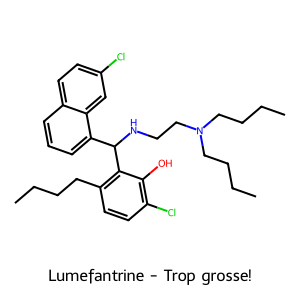

In [2]:
%matplotlib inline
from rdkit import Chem
from rdkit.Chem import Draw

mol = Chem.MolFromSmiles("CCCCN(CCCC)CCNC(C1=C2C=C(C=CC2=CC=C1)Cl)C3=C(C=CC(=C3O)Cl)CCCC")
Draw.MolToImage(mol, size=(300,300), legend="Lumefantrine - Trop grosse!")

In [3]:
from rdkit import Chem
from rdkit.Chem import Descriptors

liste = [
    ("Chloroquine", "CCN(CC)CCCC(C)NC1=C2C=CC(=CC2=NC=C1)Cl"),
    ("Hydroxychloroquine", "CCN(CCCC(C)NC1=C2C=CC(=CC2=NC=C1)Cl)CCO"),
    ("Quinine", "COC1=CC2=C(C=CN=C2C=C1)[C@H]([C@@H]3C[C@@H]4CCN3C[C@@H]4C=C)O"),
    ("Mefloquine", "FC(F)(F)C1=CC(=CC2=C(C=CN=C12)[C@H](O)[C@@H]3CCCCN3)C(F)(F)F"),
    ("Amodiaquine", "CCN(CC)CC1=C(C=CC(=C1)NC2=C3C=CC(=CC3=NC=C2)Cl)O"),
    ("Lumefantrine", "CCCCN(CCCC)CCNC(C1=C2C=C(C=CC2=CC=C1)Cl)C3=C(C=CC(=C3O)Cl)CCCC"),
    ("Artemether", "COC1OC2C(C)CCC3C2C(O1)OC1C3(C)CCC(C1)C"),
    ("Artesunate", "CC1CCC2C(C(OC3C24C1CCC(O3)(OO4)C)OC(=O)CCC(=O)O)C"),
    ("Sulfadoxine", "COC1=CC(=C(C=C1OC)OC)S(=O)(=O)NC2=NC=C(C=N2)OC"),
    ("Pyrimethamine", "CCC1=C(C(=NC(=N1)N)N)C2=CC=C(C=C2)Cl")
]

print("MEDICAMENT | POIDS | LOGP | LIPINSKI")
print("-------------------------------------")
for nom, smi in liste:
    m = Chem.MolFromSmiles(smi)
    mw = Descriptors.MolWt(m)
    logp = Descriptors.MolLogP(m)
    hbd = Descriptors.NumHDonors(m)
    hba = Descriptors.NumHAcceptors(m)
    v = (mw>500) + (logp>5) + (hbd>5) + (hba>10)
    ok = "OUI" if v<=1 else "NON"
    print(f"{nom} | {mw:.1f} | {logp:.2f} | {ok}")

MEDICAMENT | POIDS | LOGP | LIPINSKI
-------------------------------------
Chloroquine | 319.9 | 4.81 | OUI
Hydroxychloroquine | 335.9 | 3.78 | OUI
Quinine | 324.4 | 3.17 | OUI
Mefloquine | 378.3 | 4.45 | OUI
Amodiaquine | 355.9 | 5.18 | OUI
Lumefantrine | 529.6 | 8.78 | NON
Artemether | 310.4 | 3.55 | OUI
Artesunate | 384.4 | 2.60 | OUI
Sulfadoxine | 355.4 | 1.31 | OUI
Pyrimethamine | 248.7 | 2.52 | OUI


In [4]:
# installe une fois : pip install chembl_webresource_client
from chembl_webresource_client.new_client import new_client

molecule = new_client.molecule
# Cherche 5 antipaludéens utilisés au Bénin
results = molecule.filter(pref_name__icontains="Chloroquine").only(['molecule_chembl_id', 'pref_name', 'molecule_structures'])

for r in results[:3]:
    print(r['pref_name'], "->", r['molecule_structures']['canonical_smiles'])

ModuleNotFoundError: No module named 'chembl_webresource_client'

In [5]:
!pip install chembl_webresource_client


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
from chembl_webresource_client.new_client import new_client

molecule = new_client.molecule
results = molecule.filter(pref_name__icontains="Chloroquine").only(['molecule_chembl_id', 'pref_name', 'molecule_structures'])

for r in results[:5]:
    nom = r['pref_name']
    smi = r['molecule_structures']['canonical_smiles']
    print(f"{nom} -> {smi}")

ModuleNotFoundError: No module named 'chembl_webresource_client'

In [7]:
import requests

def get_smiles(nom):
    url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/{nom}/property/CanonicalSMILES/TXT"
    r = requests.get(url, timeout=10)
    return r.text.strip()

for med in ["Chloroquine", "Amodiaquine", "Lumefantrine", "Artemether"]:
    print(med, "->", get_smiles(med))

Chloroquine -> CCN(CC)CCCC(C)NC1=C2C=CC(=CC2=NC=C1)Cl
Amodiaquine -> CCN(CC)CC1=C(C=CC(=C1)NC2=C3C=CC(=CC3=NC=C2)Cl)O
Lumefantrine -> CCCCN(CCCC)CC(C1=CC(=CC2=C1C3=C(C2=CC4=CC=C(C=C4)Cl)C=C(C=C3)Cl)Cl)O
Artemether -> CC1CCC2C(C(OC3C24C1CCC(O3)(OO4)C)OC)C


In [8]:
from rdkit import Chem
from rdkit.Chem import Descriptors

smiles_dict = {
    "Chloroquine": "CCN(CC)CCCC(C)NC1=C2C=CC(=CC2=NC=C1)Cl",
    "Amodiaquine": "CCN(CC)CC1=C(C=CC(=C1)NC2=C3C=CC(=CC3=NC=C2)Cl)O"
}

for nom, smi in smiles_dict.items():
    mol = Chem.MolFromSmiles(smi)
    poids = Descriptors.MolWt(mol)
    logp = Descriptors.MolLogP(mol)
    print(f"{nom} | Poids: {poids:.1f} | LogP: {logp:.1f}")

Chloroquine | Poids: 319.9 | LogP: 4.8
Amodiaquine | Poids: 355.9 | LogP: 5.2
